# Lecture 2 — Class Exercise
# Bar Charts: World Happiness Report 2023

---

> **Your task:** Create **2 polished bar charts** using the World Happiness Report dataset.  
> **Push to:** `week02/lecture02_exercise.ipynb` in **your own GitHub repo** before the end of class.

---

### Rules to keep in mind 💡
1. Every bar chart **must have a zero baseline** — no exceptions
2. Every chart **must have an insight title**, not a topic title
3. Aim for **professional quality** — clean background, readable font, no clutter
4. Horizontal bars for long category names

---


## Setup — Run this cell first


In [1]:
import pandas as pd
import numpy as np

# World Happiness Report 2023 — representative data
# Source: https://www.kaggle.com/datasets/ajaypalsinghlo/world-happiness-report-2023

df = pd.read_csv('../data/world_happiness_2023.csv')
df.columns = ['Country','Region','Happiness_Score','GDP','Social_Support',
              'Life_Expectancy','Freedom','Generosity','Corruption']


print(f"Dataset: {len(df)} countries, {len(df.columns)} columns")
df.head()


Dataset: 63 countries, 9 columns


,Country,Region,Happiness_Score,GDP,Social_Support,Life_Expectancy,Freedom,Generosity,Corruption
0,Finland,Western Europe,7.804,10.775,0.954,71.9,0.949,0.142,0.179
1,Denmark,Western Europe,7.586,10.933,0.954,72.7,0.931,0.168,0.234
2,Iceland,Western Europe,7.525,10.878,0.983,72.5,0.961,0.260,0.150
3,Israel,Middle East and North Africa,7.473,10.527,0.916,72.4,0.903,0.149,0.826
4,Netherlands,Western Europe,7.464,11.015,0.939,72.4,0.879,0.240,0.296


In [2]:
import plotly.express as px
import plotly.graph_objects as go

# Explore the dataset before you start
print("Regions in dataset:")
print(df['Region'].value_counts())
print("\nScore range:", df['Happiness_Score'].min(), "–", df['Happiness_Score'].max())
print("\nBottom 10 countries:")
print(df.nsmallest(10, 'Happiness_Score')[['Country','Region','Happiness_Score']])


Regions in dataset:
Region
Western Europe                  15
Latin America and Caribbean     13
Central and Eastern Europe       7
Sub-Saharan Africa               7
Middle East and North Africa     6
North America and ANZ            4
Southeast Asia                   4
South Asia                       4
East Asia                        3
Name: count, dtype: int64

Score range: 1.859 – 7.804

Bottom 10 countries:
        Country                        Region  Happiness_Score
60  Afghanistan                    South Asia            1.859
61      Lebanon  Middle East and North Africa            2.392
62     Zimbabwe            Sub-Saharan Africa            2.995
52     Ethiopia            Sub-Saharan Africa            3.564
53     Tanzania            Sub-Saharan Africa            3.698
48   Bangladesh                    South Asia            3.892
47        India                    South Asia            4.036
50        Kenya            Sub-Saharan Africa            4.112
54       Uganda

---
## Task 1 — Regional Comparison Bar Chart

**What to build:** A horizontal bar chart showing the **average happiness score by region**, sorted from highest to lowest.

**Requirements:**
- Horizontal orientation (category names are long)
- Sorted by score, descending (so the happiest region is at the top)
- Zero baseline on x-axis
- At least one design choice that goes beyond the Plotly default (colour, annotation, labels, etc.)
- An insight title that answers: *which region stands out and why does it matter?*

**Hint:** Use `df.groupby('Region')['Happiness_Score'].mean()` to compute the averages.


                         Region  Happiness_Score
8                Western Europe         7.085533
4         North America and ANZ         7.018250
0    Central and Eastern Europe         6.338143
1                     East Asia         5.966000
2   Latin America and Caribbean         5.699000
6                Southeast Asia         5.695250
3  Middle East and North Africa         4.943333
7            Sub-Saharan Africa         4.064714
5                    South Asia         3.618250


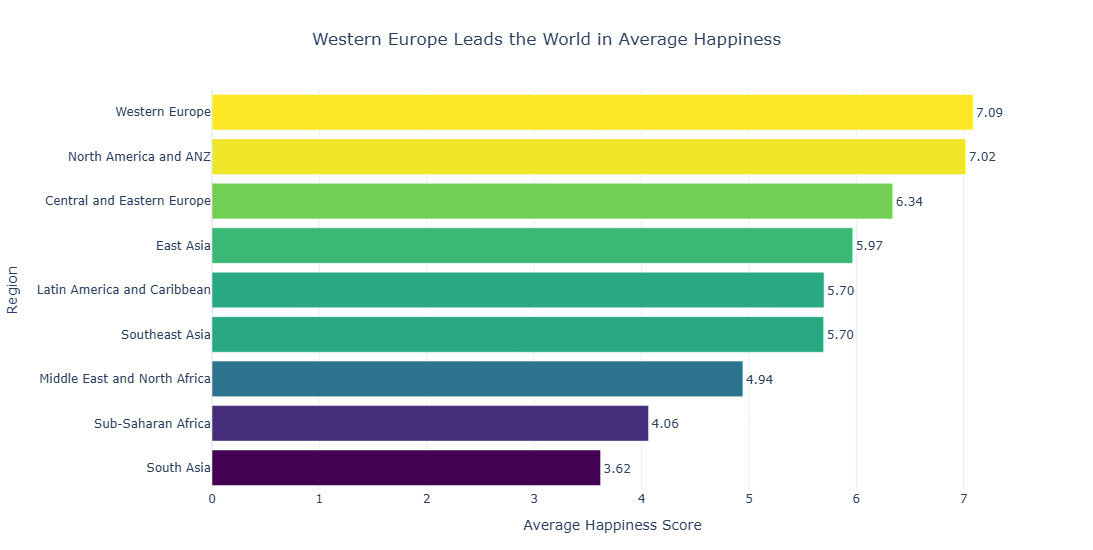

In [4]:

# Task 1: Regional comparison bar chart

# Step 1: Calculate average happiness score by region
region_avg = (
    df.groupby('Region')['Happiness_Score']
    .mean()
    .reset_index()
    .sort_values('Happiness_Score', ascending=False)
)

print(region_avg)

# Step 2: Create horizontal bar chart
fig = px.bar(
    region_avg,
    x='Happiness_Score',
    y='Region',
    orientation='h',
    color='Happiness_Score',
    color_continuous_scale='Viridis',
    text_auto='.2f',
    title='Western Europe Leads the World in Average Happiness'
)

# Step 3: Improve chart design
fig.update_traces(
    textposition='outside',
    cliponaxis=False
)

fig.update_layout(
    template='plotly_white',
    xaxis=dict(
        title='Average Happiness Score',
        rangemode='tozero'
    ),
    yaxis=dict(
        title='Region',
        autorange='reversed'
    ),
    coloraxis_showscale=False,
    title_x=0.5,
    height=550,
    margin=dict(l=160, r=80, t=90, b=60)
)

fig.show()


---
## Task 2 — Bottom vs. Top: A Contrast Story

**What to build:** A bar chart that highlights the **gap between the happiest and least happy countries**, focusing on a specific insight.

**Requirements:**
- Show the **top 8 AND bottom 8 countries** together (16 bars total)
- Use **colour** to distinguish the two groups (not Plotly's default rainbow)
- Add a **visual separator or annotation** that emphasises the gap
- Insight title that tells the story of the gap

**Hint:** Use `pd.concat([df.nlargest(8,'Happiness_Score'), df.nsmallest(8,'Happiness_Score')])` to get both groups.

**Stretch goal:** Add a vertical reference line showing the global average.


Global average: 5.81
Happiest country: Finland
Least happy country: Afghanistan
Difference: 5.95 points


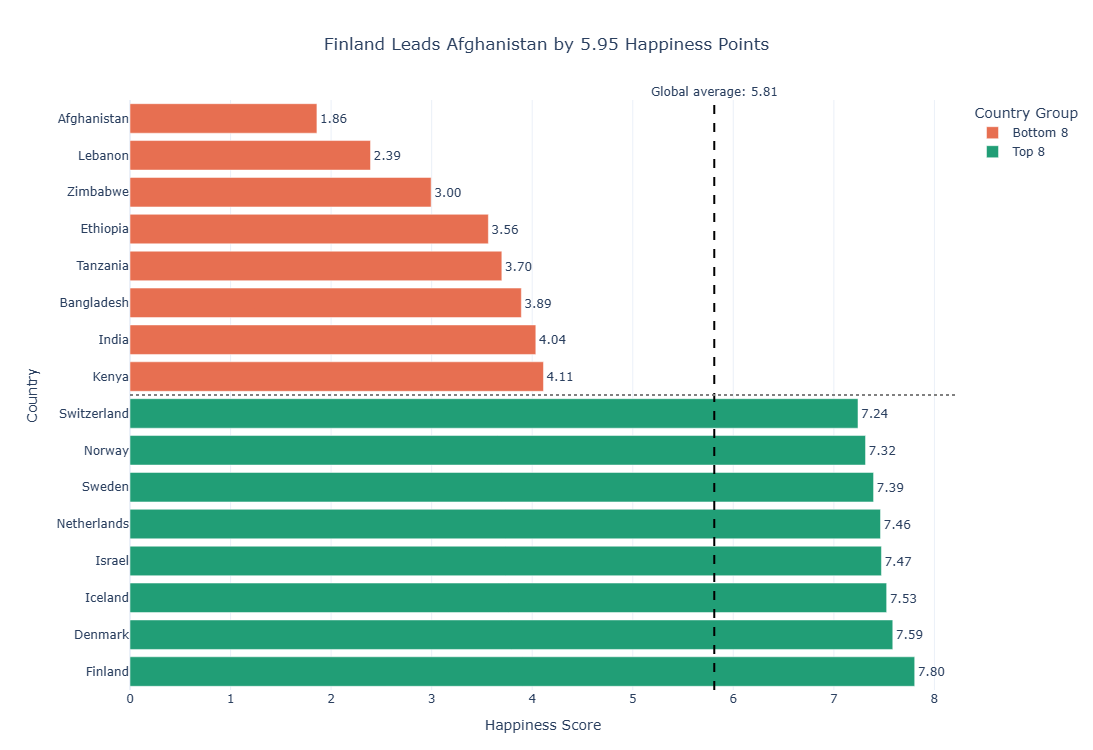

In [5]:

# Task 2: Top 8 vs Bottom 8 Happiness Comparison

# Step 1: Get top 8 and bottom 8 countries
top8 = df.nlargest(8, 'Happiness_Score').copy()
top8['Group'] = 'Top 8'

bottom8 = df.nsmallest(8, 'Happiness_Score').copy()
bottom8['Group'] = 'Bottom 8'

# Step 2: Combine both groups
combined = pd.concat([bottom8, top8]).sort_values(
    'Happiness_Score', ascending=True
).reset_index(drop=True)

# Step 3: Calculate global average and happiness gap
global_avg = df['Happiness_Score'].mean()

highest = top8.iloc[0]
lowest = bottom8.iloc[0]
gap = highest['Happiness_Score'] - lowest['Happiness_Score']

print(f"Global average: {global_avg:.2f}")
print(f"Happiest country: {highest['Country']}")
print(f"Least happy country: {lowest['Country']}")
print(f"Difference: {gap:.2f} points")

# Step 4: Create horizontal bar chart
fig = px.bar(
    combined,
    x='Happiness_Score',
    y='Country',
    color='Group',
    orientation='h',
    text_auto='.2f',
    color_discrete_map={
        'Top 8': '#219E76',
        'Bottom 8': '#E76F51'
    },
    category_orders={
        'Country': combined['Country'].tolist(),
        'Group': ['Bottom 8', 'Top 8']
    },
    title=f"{highest['Country']} Leads {lowest['Country']} by {gap:.2f} Happiness Points"
)

# Step 5: Add labels and improve design
fig.update_traces(
    textposition='outside',
    cliponaxis=False
)

fig.update_layout(
    template='plotly_white',
    xaxis=dict(
        title='Happiness Score',
        rangemode='tozero'
    ),
    yaxis=dict(
        title='Country',
        categoryorder='array',
        categoryarray=combined['Country'].tolist(),
        autorange='reversed'
    ),
    title_x=0.5,
    height=750,
    margin=dict(l=130, r=100, t=100, b=60),
    legend_title_text='Country Group'
)

# Step 6: Add global average reference line
fig.add_vline(
    x=global_avg,
    line_dash='dash',
    line_color='black',
    annotation_text=f'Global average: {global_avg:.2f}',
    annotation_position='top'
)

# Step 7: Add separator between bottom 8 and top 8
fig.add_shape(
    type='line',
    xref='paper',
    yref='paper',
    x0=0,
    x1=1,
    y0=0.5,
    y1=0.5,
    line=dict(color='gray', width=2, dash='dot')
)

fig.show()


---
## Done? Stretch Goal

If you finish both tasks with time to spare, try this:

**Task 3 (stretch):** Build a **grouped bar chart** comparing 2 sub-factors (e.g. `GDP_per_capita` and `Freedom`) across the 5 most populated regions. Use colour meaningfully and write an insight title.

Regions to include: `'Western Europe'`, `'Latin America'`, `'East Asia'`, `'Sub-Saharan Africa'`, `'South Asia'`


                        Region        GDP   Freedom
0               Western Europe  10.963533  0.896067
1  Latin America and Caribbean   9.134923  0.754231
2                    East Asia  10.312000  0.754000
3           Sub-Saharan Africa   7.082000  0.599429
4                   South Asia   7.152250  0.546250


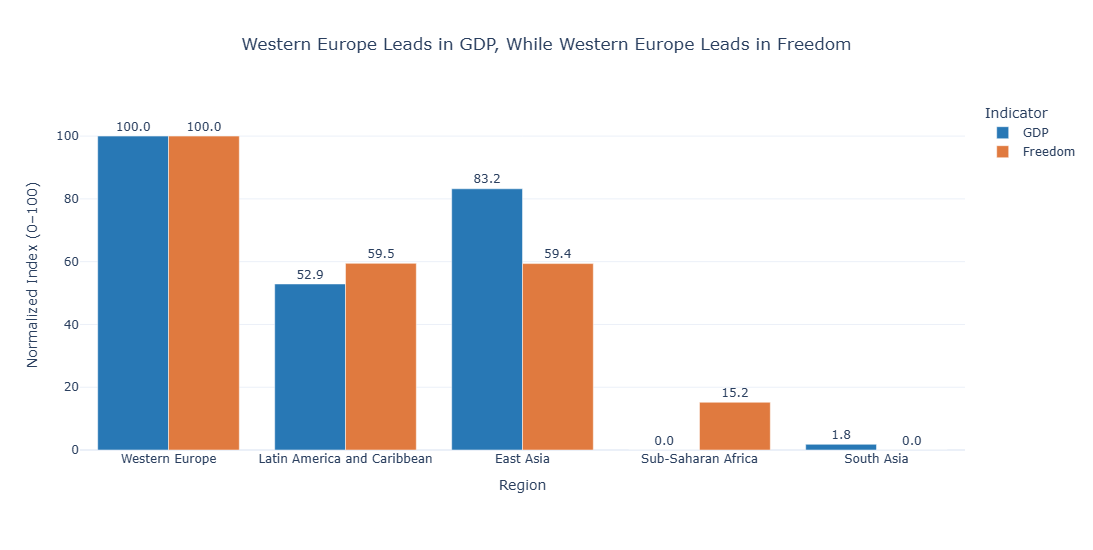

In [7]:

# Task 3: Stretch Goal - Grouped Bar Chart

# Step 1: Select the five required regions

selected_regions = [
    'Western Europe',
    'Latin America and Caribbean',
    'East Asia',
    'Sub-Saharan Africa',
    'South Asia'
]


# Step 2: Calculate regional averages
regional_data = (
    df[df['Region'].isin(selected_regions)]
    .groupby('Region')[['GDP', 'Freedom']]
    .mean()
    .reindex(selected_regions)
    .reset_index()
)

print(regional_data)

# Step 3: Normalize both measures to a 0-100 index
for column in ['GDP', 'Freedom']:
    regional_data[column + '_Index'] = (
        (regional_data[column] - regional_data[column].min()) /
        (regional_data[column].max() - regional_data[column].min())
    ) * 100

# Step 4: Prepare grouped chart data
chart_data = regional_data.melt(
    id_vars='Region',
    value_vars=['GDP_Index', 'Freedom_Index'],
    var_name='Indicator',
    value_name='Index'
)

chart_data['Indicator'] = chart_data['Indicator'].replace({
    'GDP_Index': 'GDP',
    'Freedom_Index': 'Freedom'
})

# Step 5: Find leading regions for the insight title
gdp_leader = regional_data.loc[
    regional_data['GDP'].idxmax(), 'Region'
]

freedom_leader = regional_data.loc[
    regional_data['Freedom'].idxmax(), 'Region'
]

# Step 6: Create grouped bar chart
fig = px.bar(
    chart_data,
    x='Region',
    y='Index',
    color='Indicator',
    barmode='group',
    text_auto='.1f',
    color_discrete_map={
        'GDP': '#2878B5',
        'Freedom': '#E07A3F'
    },
    title=f'{gdp_leader} Leads in GDP, While {freedom_leader} Leads in Freedom'
)

# Step 7: Improve chart design
fig.update_traces(textposition='outside')

fig.update_layout(
    template='plotly_white',
    title_x=0.5,
    xaxis_title='Region',
    yaxis_title='Normalized Index (0–100)',
    yaxis=dict(rangemode='tozero'),
    height=550,
    legend_title='Indicator',
    margin=dict(t=100, b=100)
)

fig.show()
